# Image Transformation (i.e. Image Augmentation) Example

Learn how to apply various image augmentation techniques with JAX. The
transformations are meant to be applied for each image sample when training
only, and each transformation will be performed with random parameters.

**Transformations:**
- Random flip left-right
- Random contrast, brightness, saturation and hue
- Random distortion and crop

For more information about loading data with Grain, see 'load_data.py'.

- Author: Aymeric Damien
- Project: [https://github.com/aymericdamien/JAX-Examples/](https://github.com/aymericdamien/JAX-Examples/)

In [1]:
import os
import sys

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Make the shared helpers of the 'common' folder importable.
sys.path.append(os.path.join(os.getcwd(), "..", ".."))
from common.datasets import download

In [2]:
# Download an image.
image_path = download(
    ["https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/fruits.jpg"],
    "fruits.jpg")

In [3]:
# Load image to numpy array.
img = Image.open(image_path).convert('RGB')
img_array = np.array(img)
# Convert to float32 values in [0, 1], the format used by all transformations below.
img_array = jnp.array(img_array, jnp.float32) / 255.

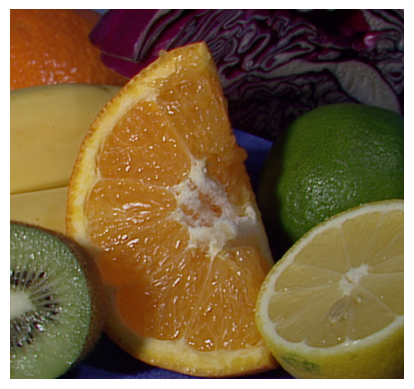

In [4]:
# Display image.
def display(image):
    plt.imshow(np.asarray(image))
    plt.axis('off')
    plt.show()

display(img_array)

In [5]:
# Each random transformation takes a random 'key' as input. A key always
# generates the same random numbers, so we split it to get a new, independent
# key for every use.
key = jax.random.key(0)

In [6]:
# Randomly flip an image.
def random_flip_left_right(key, image):
    # Flip with a probability of 50%.
    do_flip = jax.random.bernoulli(key, 0.5)
    # 'image[:, ::-1]' reverses the width axis, i.e. a left-right flip.
    return jnp.where(do_flip, image[:, ::-1], image)

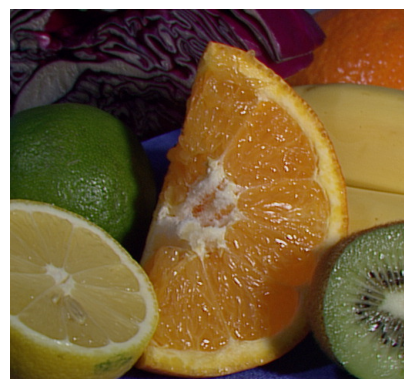

In [7]:
# Display randomly flipped image.
key, subkey = jax.random.split(key)
display(random_flip_left_right(subkey, img_array))

In [8]:
# Randomly change an image contrast.
def random_contrast(key, image, minval=0.6, maxval=1.4):
    r = jax.random.uniform(key, minval=minval, maxval=maxval)
    # Move each pixel away from (or closer to) the mean color of the image.
    mean = jnp.mean(image, axis=(0, 1), keepdims=True)
    image = (image - mean) * r + mean
    return jnp.clip(image, 0., 1.)

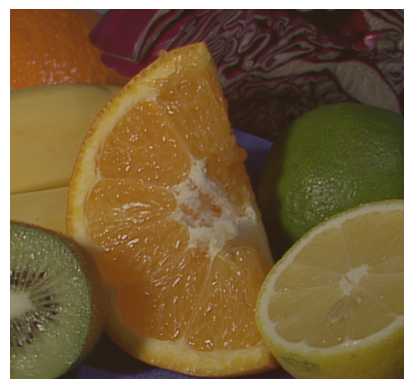

In [9]:
# Display image with different contrast.
key, subkey = jax.random.split(key)
display(random_contrast(subkey, img_array))

In [10]:
# Randomly change an image brightness.
def random_brightness(key, image, minval=0., maxval=.2):
    r = jax.random.uniform(key, minval=minval, maxval=maxval)
    # Add the same value to every pixel.
    image = image + r
    return jnp.clip(image, 0., 1.)

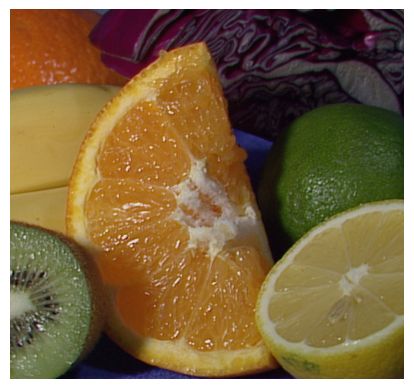

In [11]:
# Display image with different brightness.
key, subkey = jax.random.split(key)
display(random_brightness(subkey, img_array))

In [12]:
# Saturation and hue are easier to change in the HSV color space, where
# each pixel is described by its Hue (its color, as an angle on the color
# wheel, in [0, 1)), its Saturation (from gray to vivid) and its Value
# (brightness). These two functions convert images between RGB and HSV.
def rgb_to_hsv(image):
    red, green, blue = image[..., 0], image[..., 1], image[..., 2]
    value = jnp.max(image, axis=-1)
    delta = value - jnp.min(image, axis=-1)
    saturation = jnp.where(value > 0., delta / jnp.maximum(value, 1e-12), 0.)
    # The hue depends on which channel is the largest (0 = red, 1/3 = green,
    # 2/3 = blue). Gray pixels (delta = 0) have no hue: use 0.
    d = jnp.maximum(delta, 1e-12)
    hue = jnp.where(value == red, (green - blue) / d,
                    jnp.where(value == green, 2. + (blue - red) / d, 4. + (red - green) / d))
    hue = jnp.where(delta > 0., (hue / 6.) % 1., 0.)
    return jnp.stack([hue, saturation, value], axis=-1)

def hsv_to_rgb(image):
    hue, saturation, value = image[..., 0:1], image[..., 1:2], image[..., 2:3]
    # Position of each channel (red, green, blue) relative to the hue.
    k = (jnp.array([5., 3., 1.]) + hue * 6.) % 6.
    return value - value * saturation * jnp.clip(jnp.minimum(k, 4. - k), 0., 1.)

In [13]:
# Randomly change an image saturation.
def random_saturation(key, image, minval=0.4, maxval=2.):
    r = jax.random.uniform(key, minval=minval, maxval=maxval)
    hsv = rgb_to_hsv(image)
    # Multiply the saturation by 'r' (more vivid if r > 1, grayer if r < 1).
    hsv = hsv.at[..., 1].set(jnp.clip(hsv[..., 1] * r, 0., 1.))
    return hsv_to_rgb(hsv)

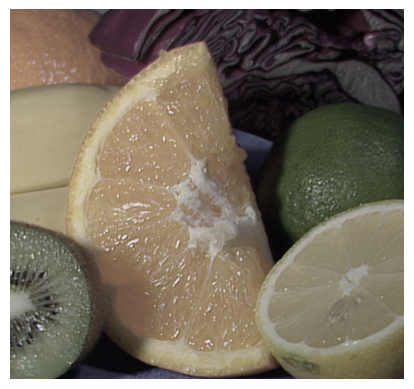

In [14]:
# Display image with different saturation.
key, subkey = jax.random.split(key)
display(random_saturation(subkey, img_array))

In [15]:
# Randomly change an image hue.
def random_hue(key, image, minval=-0.04, maxval=0.08):
    r = jax.random.uniform(key, minval=minval, maxval=maxval)
    hsv = rgb_to_hsv(image)
    # Shift the hue by 'r' (a fraction of a full turn of the color wheel).
    hsv = hsv.at[..., 0].set((hsv[..., 0] + r) % 1.)
    return hsv_to_rgb(hsv)

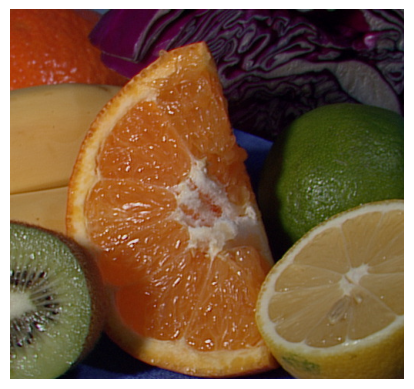

In [16]:
# Display image with different hue.
key, subkey = jax.random.split(key)
display(random_hue(subkey, img_array))

In [17]:
# Distort an image by cropping it with a different aspect ratio.
# Note: unlike the other transformations, it can't be compiled with 'jax.jit',
# as the size of its output depends on random values. Use it on the CPU, in
# the input pipeline (e.g. in a Grain 'map', see 'load_data.py').
def distorted_random_crop(key,
                          image,
                          min_object_covered=0.1,
                          aspect_ratio_range=(3. / 4., 4. / 3.),
                          area_range=(0.06, 1.0),
                          max_attempts=100):
    height, width = image.shape[0], image.shape[1]
    for attempt_key in jax.random.split(key, max_attempts):
        area_key, ratio_key, y_key, x_key = jax.random.split(attempt_key, 4)
        # Pick a random area (a fraction of the image) and aspect ratio.
        area = jax.random.uniform(area_key, minval=area_range[0], maxval=area_range[1])
        aspect_ratio = jax.random.uniform(ratio_key, minval=aspect_ratio_range[0],
                                          maxval=aspect_ratio_range[1])
        # Deduce the crop size (width / height = aspect_ratio).
        crop_height = int(jnp.round(jnp.sqrt(area * height * width / aspect_ratio)))
        crop_width = int(jnp.round(jnp.sqrt(area * height * width * aspect_ratio)))
        # Retry if the crop doesn't fit in the image, or if it covers less
        # than 'min_object_covered' of the image.
        if (crop_height > height or crop_width > width
                or crop_height * crop_width < min_object_covered * height * width):
            continue
        # Pick a random position for the crop.
        y = int(jax.random.randint(y_key, (), 0, height - crop_height + 1))
        x = int(jax.random.randint(x_key, (), 0, width - crop_width + 1))
        # Crop the image to that bounding box.
        return image[y:y + crop_height, x:x + crop_width]
    # No valid crop found: keep the whole image.
    return image

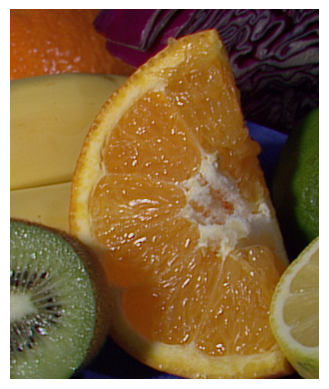

In [18]:
# Display cropped image.
key, subkey = jax.random.split(key)
display(distorted_random_crop(subkey, img_array))

In [19]:
# Apply all transformations to an image.
# That is a common image augmentation technique for image datasets, such as ImageNet.
def transform_image(key, image):
    keys = jax.random.split(key, 6)
    image = distorted_random_crop(keys[0], image)
    image = random_flip_left_right(keys[1], image)
    image = random_contrast(keys[2], image)
    image = random_brightness(keys[3], image)
    image = random_hue(keys[4], image)
    image = random_saturation(keys[5], image)
    return image

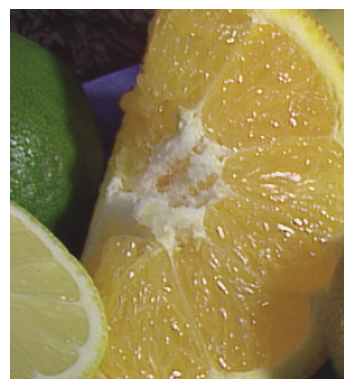

In [20]:
# Display fully pre-processed image.
key, subkey = jax.random.split(key)
transformed_img = transform_image(subkey, img_array)
display(transformed_img)

In [21]:
# Resize transformed image to a 256x256px square image, ready for training.
def resize_image(image):
    return jax.image.resize(image, shape=(256, 256, 3), method='bilinear')

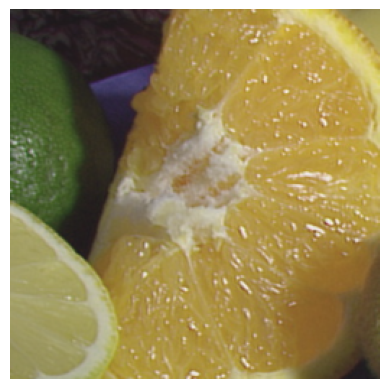

In [22]:
# Display resized image.
display(resize_image(transformed_img))